# 第二步：让 Blender 管场景和相机

写渲染算法需要场景：模型、材质颜色、相机、灯光。这些不必自己造轮子。
Blender 可以作为一个 Python 模块（`bpy`）直接跑在 notebook 的运行时里，没有窗口。分工是：

- **Blender**：场景和相机。可以用它的 Python 接口搭，也可以打开你在 Blender 里做好的 `.blend` 文件。
- **这里**：渲染算法。你写着色器，画面在你的浏览器里实时运行。
- **Blender 还负责出标准答案**：它自己的光线求交和 Cycles 渲染器，用来核对我们画得对不对。

和上一本一样，下面的画面随文件保存，不连运行时也是活的。

In [1]:
%pip install -q bpy git+https://github.com/x380kkm/colabgraphics@dev
import numpy as np
from PIL import Image
import colabgraphics as cg
from colabgraphics import blender

## 场景

`demo_scene()` 用 Blender 自带的几何体搭一个小场景：猴头、地面、一个方块、一台相机、一盏太阳灯。
换成自己的场景只要一行：`blender.open("我的场景.blend")`。

`scene()` 把当前场景取成 numpy 数组：世界空间里的三角形（位置、法线、UV、材质颜色），
相机的视图矩阵和投影矩阵，以及灯光。

In [2]:
blender.demo_scene()
data = blender.scene(resolution=(512, 384))
print(data)
for name, first, count in data.objects:
    print(f"  {name:10s} {count // 3:5d} 个三角形")
print("相机位置", data.camera.position.round(2), "  近/远裁剪面", data.camera.clip)
sun = data.lights[0]
print("太阳照射方向", sun.direction.round(2))

SceneData(982 triangles in 3 objects, camera 'Camera', 1 lights, 512x384)
  Suzanne      968 个三角形
  Plane          2 个三角形
  Cube          12 个三角形
相机位置 [ 3.2 -4.   2.2]   近/远裁剪面 (0.10000000149011612, 1000.0)
太阳照射方向 [-0.55  0.28 -0.79]


## 用自己的着色器画它

网格交给 `mesh()`，相机矩阵交给 `var()`。顶点着色器里的 `Vertex` 结构体由系统声明
（`position`、`normal`、`uv`、`color`）。矩阵按数学上的习惯给：着色器里的 `mul(矩阵, 列向量)`
等于 numpy 里的 `矩阵 @ 向量`。

一个 pass 同时写三张纹理（`SV_Target0` 到 `SV_Target2`）：着色结果、法线、离相机的距离。
点画面下方的纹理名可以分别看；鼠标停在画面上会显示该像素的数值，比如在 `view_depth` 上读到的就是以场景单位计的距离。

太阳的方位和高度做成了变量，初始值取自 Blender 里那盏灯。拖一拖看看。

In [3]:
SHADER = """
struct VSOut
{
    float4 position : SV_Position;
    float3 world    : TEXCOORD0;
    float3 normal   : NORMAL;
    float3 color    : COLOR0;
};

struct PSOut
{
    float4 color  : SV_Target0;
    float4 normal : SV_Target1;
    float  depth  : SV_Target2;
};

VSOut VSMain(Vertex v)
{
    VSOut o;
    o.position = mul(vars.view_projection, float4(v.position, 1));
    o.world = v.position;
    o.normal = v.normal;
    o.color = v.color;
    return o;
}

PSOut PSMain(VSOut input)
{
    float3 n = normalize(input.normal);
    float3 to_sun = float3(cos(vars.sun_elevation) * cos(vars.sun_azimuth),
                           cos(vars.sun_elevation) * sin(vars.sun_azimuth),
                           sin(vars.sun_elevation));
    float3 lit = input.color * (vars.ambient + (1.0 - vars.ambient) * max(dot(n, to_sun), 0.0));
    PSOut o;
    o.color = float4(pow(lit, 1.0 / 2.2), 1);
    o.normal = float4(n * 0.5 + 0.5, 1);
    o.depth = -mul(vars.view, float4(input.world, 1)).z;   // 相机前方的距离
    return o;
}
"""

to_sun = -sun.direction
t = cg.Technique("blender_scene")
w, h = data.resolution
color = t.texture("color", size=(w, h))
normal = t.texture("normal", size=(w, h))
view_depth = t.texture("view_depth", size=(w, h), format="r32float")
mesh = t.mesh("scene", data.positions, data.normals, data.uvs, data.colors)

t.var("view_projection", data.camera.view_projection)
t.var("view", data.camera.view.astype(np.float32))
t.var("sun_azimuth", float(np.arctan2(to_sun[1], to_sun[0])), min=-3.14, max=3.14, doc="太阳方位角，弧度")
t.var("sun_elevation", float(np.arcsin(to_sun[2])), min=0.0, max=1.57, doc="太阳高度角，弧度")
t.var("ambient", 0.15, min=0.0, max=1.0)

t.draw("raster", SHADER, targets=[color, normal, view_depth], mesh=mesh, depth=True, cull="back")
t.show(color)

<colabgraphics technique 'blender_scene'>

## 和 Blender 自己的渲染放在一起

左边是上面的技术在运行时这一侧无头执行的结果，右边是 Blender 的 Cycles 渲染器对同一个场景、同一台相机的渲染。
几何和取景完全一致。差别在光照：Cycles 有阴影和间接光，我们目前只有最简单的漫反射。
把差别一点点补上，就是后面几章的内容。

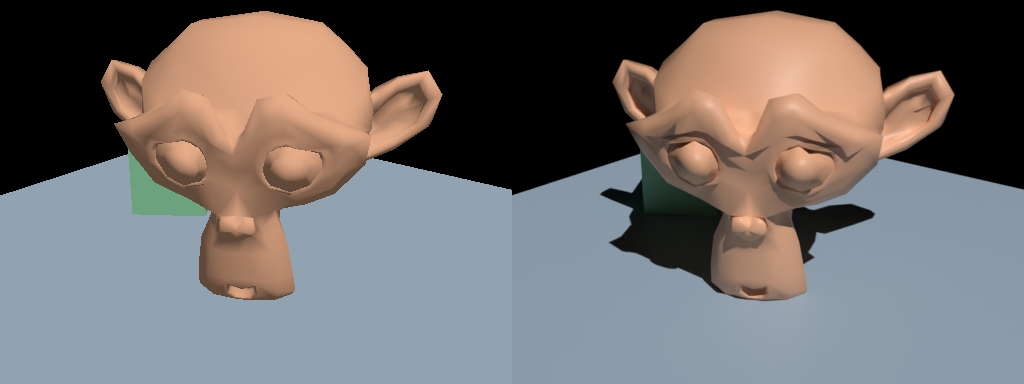

In [4]:
ours = t.read(color)
cycles = blender.render(resolution=(w, h), samples=48)
Image.fromarray(np.hstack([ours, cycles]))

## 数值核对

看着像不等于对。`reference()` 让 Blender 对每个像素的中心发一条射线，返回它打到的位置。
这份答案完全不经过我们的渲染代码，所以可以拿来核对：哪些像素被覆盖、每个像素离相机多远。

In [5]:
ours_depth = t.read(view_depth)[..., 0]
ref = blender.reference(resolution=(w, h))

covered = ours_depth > 0
iou = (covered & ref["hit"]).sum() / (covered | ref["hit"]).sum()
print(f"覆盖范围的重合度（交并比）: {iou:.4f}")

both = covered & ref["hit"]
error = np.abs(ours_depth - ref["depth"])[both]
print(f"深度误差: 中位数 {np.median(error):.6f}，95% 的像素小于 {np.percentile(error, 95):.4f}（场景单位）")
print(f"误差较大的像素都在物体轮廓上: 那里一个像素内本来就有两个深度。共比较 {both.sum()} 个像素。")

覆盖范围的重合度（交并比）: 0.9999
深度误差: 中位数 0.000041，95% 的像素小于 0.0002（场景单位）
误差较大的像素都在物体轮廓上: 那里一个像素内本来就有两个深度。共比较 147754 个像素。
